# 11 · Did prices really shift at each event?

**Milestone 4, item 4.3** · see `docs/MILESTONES.md`

## What we're looking for

Notebook 08 lined events up with price charts and found some big moves. It also showed
the problem with that: when a price is already rising, *any* event during the rise looks
big. This notebook asks a sharper question:

> **After each event, was the price different from what it would have been without it?**

We can't see the world without the event, so we estimate it. The method has four steps:

1. **Learn the pattern before the event.** Take the 3 years of prices before the event
   started, and fit a simple model of how the price was moving: its trend, and how much
   each month carries over from the last.
2. **Predict the next 6 months as if nothing happened.** This is the *forecast*: our best
   guess of the price without the event.
3. **Measure the gap.** Compare the actual price with the forecast, averaged over the 6
   months after the event started. A gap of +10% means prices ran 10% above where they
   were heading.
4. **Decide whether the gap is unusual.** Run exactly the same steps for **every other
   month** since 2018, events or not, and see how often a gap that big turns up by
   chance. If fewer than 5% of ordinary months have a gap that big, we call it a
   **clear shift**.

Prices are **inflation-adjusted** (D27), so general inflation can't make an event look
bigger than it was. Step 4 matters most, and section 3 shows why.

**Sections**
1. Setup
2. One event, step by step (COVID closures and pork)
3. Why we don't trust the model's own error range
4. The test for every event
5. A second opinion: a simpler forecast
6. What we found, and what's next

## Reading guide (no statistics background needed)

**What this notebook does:** for each event, it asks whether the price ended up
different from where it was already heading, and whether that difference is bigger than
the normal month-to-month wobble.

**Words you'll see:**
- **Forecast:** our best guess of where the price was heading if the event hadn't
  happened, based on the three years before it.
- **Gap:** how far the actual price ran above (+) or below (−) that forecast, on average
  over the next six months.
- **Ordinary months:** months with no event nearby. They show how big a gap can be just
  by chance.
- **P-value:** the share of ordinary months with a gap at least as big as the event's.
  Small means unusual. Below 0.05 (fewer than 1 in 20) counts as a **clear shift**;
  0.05 to 0.10 is a **possible shift**.
- **AR(1) with a trend:** the forecasting method: a straight-line trend, plus the
  tendency of a high month to be followed by another high month.
- **Placebo test (section 3):** running the same check on ordinary months, to see how
  often it raises a false alarm. It caught that the forecast's own error range was far
  too confident.

**If you only read one part:** section 6, *What we found*.

**Want the whole project in plain language?** See *Findings and methods explained*: `docs/FINDINGS.md` in the repo, or **Docs** in the bar at the top of the project site.

## 1 · Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import find_dotenv
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")  # statsmodels warns about date frequency; we pass plain arrays

env_path = find_dotenv()
PROJECT_ROOT = Path(env_path).parent if env_path else Path.cwd().parent
PROCESSED = PROJECT_ROOT / "data" / "processed"
df = pd.read_csv(PROCESSED / "master_monthly.csv", parse_dates=["date"]).set_index("date")
events = pd.read_csv(PROCESSED / "events.csv", parse_dates=["start_date", "end_date"])

MEATS = {"beef": "Ground beef", "pork": "Pork chops", "chicken": "Chicken breast"}
COLORS = {"beef": "#9A3B2E", "pork": "#2F6690", "chicken": "#C08A1E"}
prices = df.loc["2015":]
BASE_MONTH = df["cpi_all_items"].last_valid_index()

PRE = 36    # months of history used to learn the pattern before each event
AFTER = 6   # months after the event start that we compare with the forecast
SEED = 2026

print(f"Prices {prices.index.min():%b %Y} to {prices.index.max():%b %Y}, in {BASE_MONTH:%B %Y} dollars. "
      f"First month that can be tested: {prices.index[PRE]:%b %Y}")

Prices Jan 2015 to Sep 2026, in September 2026 dollars. First month that can be tested: Jan 2018


### How to read it
Because the model needs 3 years of history, the first month we can test is January 2018.
That rules out only the 2011–2013 drought, which notebook 08 already showed acts slowly
through the herd (item 4.4 covers it).

## 2 · One event, step by step

**What we're looking for:** what the method actually does, shown on one event: the
COVID-19 plant closures (April 2020) and pork chops, the biggest jump in notebook 08.

**The model.** The forecast comes from a small time-series model, an **AR(1) with a
trend**. In plain terms: *next month's price = a straight-line trend + a share of how far
this month was above or below that trend + a random wiggle.* The "share" captures how
prices stick: a high month tends to be followed by another high month. We fit it to the
log of the price, so gaps come out as percentages.

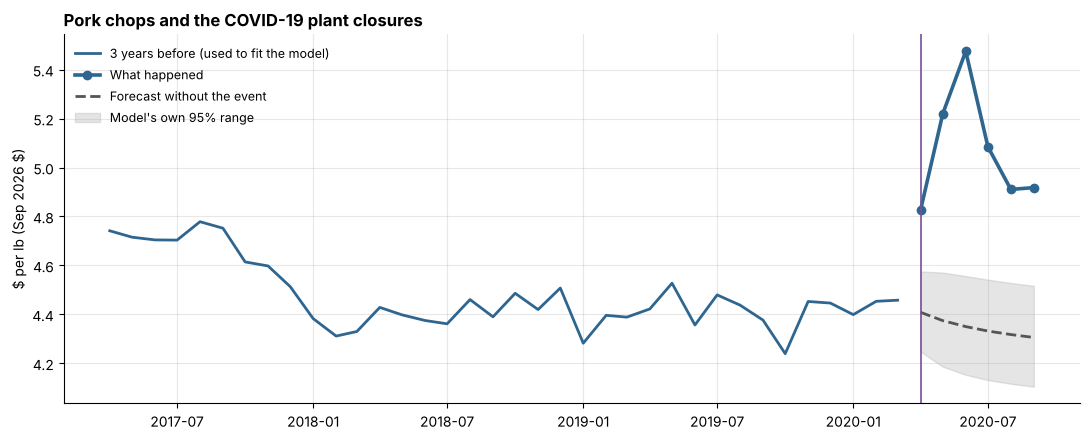

Average gap over the 6 months from Apr 2020: +16.6%
Model: trend -0.8% per year (approx.), carry-over share 0.63


In [2]:
def forecast(meat, month, pre=PRE, after=AFTER):
    """Fit AR(1) + trend to the `pre` months before `month`; forecast up to `after` months from `month`.

    Returns the history, the actual prices after, the forecast, and the fitted model (all in logs).
    """
    y = np.log(prices[f"{meat}_price_real"])
    t = y.index.get_loc(month)
    history, actual = y.iloc[t - pre:t], y.iloc[t:t + after]
    model = SARIMAX(history.values, order=(1, 0, 0), trend="ct").fit(disp=False)
    predicted = pd.Series(model.get_forecast(len(actual)).predicted_mean, index=actual.index)
    return history, actual, predicted, model


def gap_pct(actual, predicted):
    """Average gap between actual and forecast, as a percent (from the average log difference)."""
    return (np.exp((actual - predicted).mean()) - 1) * 100


month = pd.Timestamp("2020-04-01")
history, actual, predicted, model = forecast("pork", month)
band = model.get_forecast(len(actual)).conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(np.exp(history), color=COLORS["pork"], linewidth=2, label="3 years before (used to fit the model)")
ax.plot(np.exp(actual), color=COLORS["pork"], linewidth=2.6, marker="o", label="What happened")
ax.plot(np.exp(predicted), color="#555555", linestyle="--", linewidth=2, label="Forecast without the event")
ax.fill_between(actual.index, np.exp(band[:, 0]), np.exp(band[:, 1]), color="#999999", alpha=0.25,
                label="Model's own 95% range")
ax.axvline(month, color="#7A4E9C", linewidth=1.2)
ax.set_ylabel(f"$ per lb ({BASE_MONTH:%b %Y} $)".replace("$", r"\$"))
ax.set_title("Pork chops and the COVID-19 plant closures", loc="left", fontweight="bold")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.grid(alpha=0.3)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

print(f"Average gap over the {len(actual)} months from {month:%b %Y}: {gap_pct(actual, predicted):+.1f}%")
print(f"Model: trend {dict(zip(model.model.param_names, model.params))["drift"] * 1200:+.1f}% per year (approx.), carry-over share {dict(zip(model.model.param_names, model.params))["ar.L1"]:.2f}")

### How to read it
The thin line on the left is the 3 years of pork prices the model learned from. The
dashed line is where the model expected prices to go without the event, and the gray
band is the model's own idea of how far off it could be. The dots are what actually
happened. The printed gap is the average distance between the dots and the dashed line.

### What it means
Before the closures, pork had been drifting slightly down, and the model expected that to continue (dashed line). Instead the price jumped to about $5.48 a pound by June 2020, in today's dollars, then fell back. Even after the drop it was still above the forecast in September. Averaged over the six months, pork ran **16.6% above where it was heading**, far outside the model's gray band.

That's the method in one picture: the forecast stands in for "no event", and the gap is the event's effect. The open question is how big a gap has to be before we believe it, which is the next section.

## 3 · Why we don't trust the model's own error range

**What we're looking for:** a fair test should rarely cry wolf. If we test a month where
nothing in particular happened, it should call it a "clear shift" only about 5% of the
time (that's what a 5% threshold means).

So we run a **placebo test**: apply the method to **every month** from 2018 on, not just
event months, and count how often each month's gap falls outside the model's own 95%
range. To get that range for a 6-month *average* gap, we simulate 2,000 possible futures
from the fitted model and see where 95% of their average gaps fall.

In [3]:
def model_range(model, months, n=2000, seed=SEED):
    """95% range of the average log gap over `months`, simulated from the fitted AR(1) model."""
    params = dict(zip(model.model.param_names, model.params))
    rng = np.random.default_rng(seed)
    shocks = rng.normal(0, np.sqrt(params["sigma2"]), (n, months))
    errors = np.zeros((n, months))
    carry = np.zeros(n)
    for k in range(months):
        carry = params["ar.L1"] * carry + shocks[:, k]
        errors[:, k] = carry
    return np.percentile(errors.mean(axis=1), [2.5, 97.5])


placebo_rows = []
for meat in MEATS:
    for month in prices.index[PRE:len(prices) - 2]:  # need at least 3 months after
        history, actual, predicted, model = forecast(meat, month)
        low, high = model_range(model, len(actual))
        log_gap = (actual - predicted).mean()
        placebo_rows.append({"meat": meat, "month": month, "gap_pct": gap_pct(actual, predicted),
                             "outside_model_range": not (low <= log_gap <= high)})
placebo = pd.DataFrame(placebo_rows)

false_alarms = placebo.groupby("meat")["outside_model_range"].mean().mul(100).round(0)
print("Share of ALL months the model's own range would flag as a shift (should be about 5%):")
print(false_alarms.rename("% of months flagged").to_string())

Share of ALL months the model's own range would flag as a shift (should be about 5%):
meat
beef       27.0
chicken    36.0
pork       33.0


### How to read it
Each number is the share of months, from 2018 on, where the actual price ended up
outside the model's own 95% range. If the range were honest, that share would be close
to 5% (and a bit higher, since a few of those months really did have events).

### What it means
The model's own range is **far too confident**. It would flag **27–36% of all months** as a shift, when an honest range would flag about 5%. If we used it, a third of all months would look like "events".

The reason is that the range assumes the model is exactly right and the next 6 months behave like the last 3 years. Real prices change course more often than that: a trend bends, a shock arrives that no one named. This is a common trap with forecast intervals, and it's why notebook 08's simple ranking and this placebo check matter.

**The fix:** judge each event's gap against the gaps at **ordinary months**, using the same method. Then an event counts as a clear shift only if its gap is bigger than what usually happens with no named event, whatever the model thinks its own error is.

## 4 · The test for every event

**What we're looking for:** for each event and each meat it should affect, the gap
between actual and forecast prices, and how unusual that gap is **compared with ordinary
months**.

**Droughts are not tested here.** They last years and work through the herd, so a
6-month window is the wrong tool (item 4.4 tests them). Notebook 08 also showed the
problem in practice: the 2020 drought starts just as the COVID spike was fading, so its
"gap" would measure the fade, not the drought. The government shutdown is left out too,
because it interrupted data collection, not prices.

The comparison group is every placebo month from section 3, **except** months within 6
months of the start of an event affecting that meat, so the events don't make
"ordinary" months look wilder than they were.

The **p-value** is the share of ordinary months with a gap at least as big as the
event's, in either direction (counting the event itself, so it's never exactly zero).
Small means unusual:
- **below 0.05:** clear shift (fewer than 1 in 20 ordinary months had a gap that big)
- **0.05 to 0.10:** possible shift
- **above 0.10:** no clear shift

In [4]:
# Droughts act slowly through the herd (item 4.4); the shutdown interrupted data, not prices
tested = events[~events["category"].isin(["weather", "data"])].copy()
tested["month"] = tested["start_date"].dt.to_period("M").dt.to_timestamp()
tested["meat_list"] = tested["meats"].str.split(";")

# For each meat, months within 6 months of one of ITS events are left out of the comparison group
near_event = {meat: set() for meat in MEATS}
for _, e in tested.iterrows():
    window = pd.date_range(e["month"] - pd.DateOffset(months=AFTER), e["month"] + pd.DateOffset(months=AFTER), freq="MS")
    for meat in e["meat_list"]:
        near_event[meat] |= set(window)
ordinary = placebo[[m not in near_event[meat] for meat, m in zip(placebo["meat"], placebo["month"])]]
print("Ordinary months in the comparison group:", ordinary.groupby("meat").size().to_dict())


def p_value(gap, pool):
    # Share of ordinary months with a gap at least as big (either direction), counting the event itself
    return ((pool >= abs(gap)).sum() + 1) / (len(pool) + 1)


def verdict(p):
    return "clear shift" if p < 0.05 else "possible shift" if p < 0.10 else "no clear shift"


rows = []
for _, e in tested.iterrows():
    for meat in e["meat_list"]:
        if e["month"] < prices.index[PRE] or e["month"] > prices.index[-3]:
            continue  # not enough history before, or not enough months after
        history, actual, predicted, model = forecast(meat, e["month"])
        gap = gap_pct(actual, predicted)
        pool = ordinary.loc[ordinary["meat"] == meat, "gap_pct"].abs()
        p = p_value(gap, pool)
        rows.append({"event_id": e["event_id"], "event": e["event"][:45], "meat": meat,
                     "start": f"{e['month']:%b %Y}", "months_after": len(actual),
                     "gap_pct": round(gap, 1), "p_value": round(p, 3), "verdict": verdict(p),
                     "popular_claim": e["popular_explanation"]})
results = pd.DataFrame(rows).set_index("event_id")
results

Ordinary months in the comparison group: {'beef': 31, 'chicken': 56, 'pork': 66}


,event,meat,start,months_after,gap_pct,p_value,verdict,popular_claim
event_id,,,,,,,,
E02,"Tyson beef plant fire, Holcomb, Kansas",beef,Aug 2019,6,1.1,0.812,no clear shift,no
E03,COVID-19 meatpacking plant closures,beef,Apr 2020,6,11.0,0.031,clear shift,no
E03,COVID-19 meatpacking plant closures,pork,Apr 2020,6,16.6,0.015,clear shift,no
E03,COVID-19 meatpacking plant closures,chicken,Apr 2020,6,12.8,0.018,clear shift,no
E05,JBS ransomware cyberattack,beef,May 2021,6,3.4,0.375,no clear shift,no
E05,JBS ransomware cyberattack,pork,May 2021,6,1.0,0.761,no clear shift,no
E06,Russia invades Ukraine; grain and feed prices,chicken,Feb 2022,6,8.4,0.035,clear shift,no
E06,Russia invades Ukraine; grain and feed prices,pork,Feb 2022,6,-4.6,0.134,no clear shift,no
E06,Russia invades Ukraine; grain and feed prices,beef,Feb 2022,6,0.3,0.938,no clear shift,no


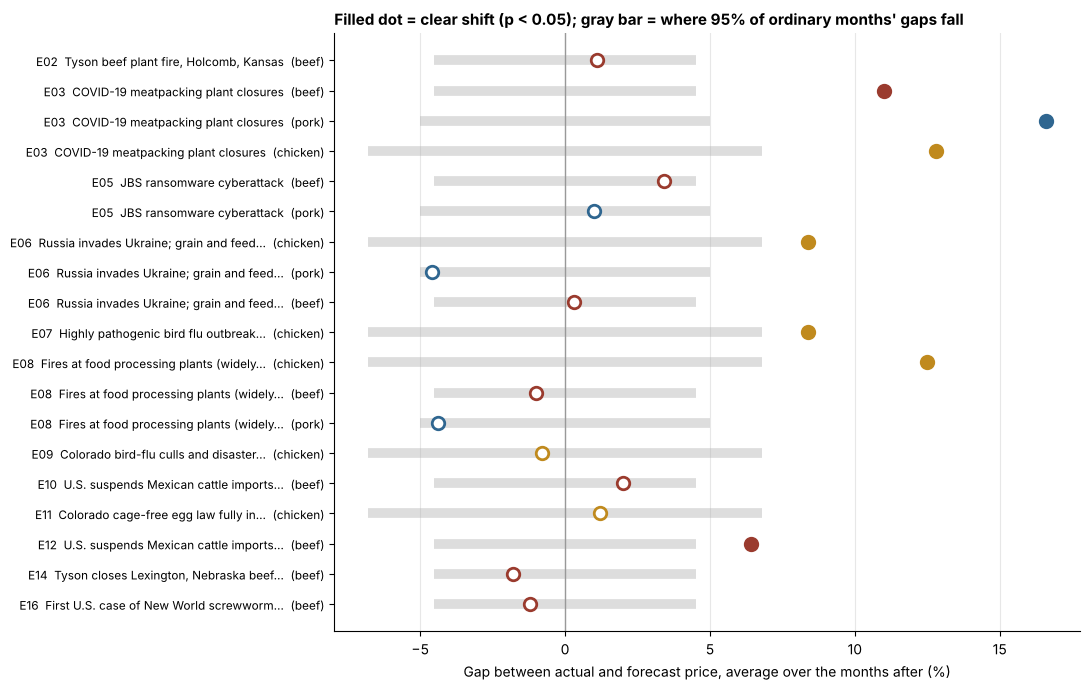

95% of ordinary months' gaps fall within: {'beef': '±4.5%', 'pork': '±5.0%', 'chicken': '±6.8%'}


In [5]:
from textwrap import shorten

fig, ax = plt.subplots(figsize=(11, 7))
ordered = results.reset_index().iloc[::-1].reset_index(drop=True)
edges = {meat: ordinary.loc[ordinary["meat"] == meat, "gap_pct"].abs().quantile(0.95) for meat in MEATS}
for i, r in ordered.iterrows():
    color = COLORS[r["meat"]]
    edge = edges[r["meat"]]
    ax.plot([-edge, edge], [i, i], color="#dddddd", linewidth=7, solid_capstyle="butt", zorder=1)
    filled = r["verdict"] == "clear shift"
    ax.plot(r["gap_pct"], i, marker="o", markersize=9, color=color, zorder=2,
            markerfacecolor=color if filled else "white", markeredgewidth=2)
ax.axvline(0, color="#999999", linewidth=1)
ax.set_yticks(range(len(ordered)))
ax.set_yticklabels([f"{r['event_id']}  {shorten(r['event'], 40, placeholder='…')}  ({r['meat']})"
                    for _, r in ordered.iterrows()], fontsize=8.5)
ax.set_xlabel("Gap between actual and forecast price, average over the months after (%)")
ax.set_title("Filled dot = clear shift (p < 0.05); gray bar = where 95% of ordinary months' gaps fall",
             loc="left", fontweight="bold", fontsize=11)
ax.grid(axis="x", alpha=0.3)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()
print("95% of ordinary months' gaps fall within:", {m: f"±{v:.1f}%" for m, v in edges.items()})

### How to read it
In the table, **gap_pct** is how far the actual price ran above (+) or below (−) the
forecast, averaged over the months after the event (up to 6). **p_value** is the share of
ordinary months with a gap at least that big. In the chart, each dot is one event and
meat. The gray bar behind each dot shows where 95% of that meat's ordinary months fall,
so a dot outside its bar is unusual. Filled dots are clear shifts.

### What it means
In ordinary months, 95% of gaps fall within about **±4.5% for beef, ±5% for pork and ±7% for chicken**. Measured against that:

**Clear shifts:**
- **COVID-19 plant closures (E03), all three meats:** beef +11%, pork +17%, chicken +13% above the forecast. These are the biggest gaps in the table for each meat. For beef, p = 0.031 is the smallest the test can produce (see Limits).
- **Chicken in 2022 (E06 feed costs, E07 bird flu, E08 fires claim):** +8% to +13%. These are the same price spike tested three times, so the test confirms the spike was real but can't say which event caused it. The feed-cost surge didn't shift pork (−4.6%) or beef (+0.3%) within six months. One likely reason is that chickens reach market weight in about seven weeks, so higher feed costs reach chicken prices much sooner than pork or beef.
- **Second Mexican cattle import suspension (E12, May 2025):** beef +6.4% above a forecast that already expected it to rise. It's just outside the ordinary range, and section 5 rates it less firmly.

**No clear shift:** the 2019 Tyson fire, the JBS attack (beef +3.4%, inside the ordinary range), the first import suspension, the 2026 Tyson closure, the screwworm case, and two of the popular claims (Colorado culls, cage-free law).

**The fires claim (E08):** chicken shows a shift, but that's the 2022 spike again. Beef and pork, which the claim also covers, show nothing. If plant fires were driving prices, all three would have moved.

## 5 · A second opinion: a simpler forecast

**What we're looking for:** whether the verdicts depend on the choice of model. Here's a
much simpler forecast: start from the last month before the event and continue at the
**average monthly change** of the previous 3 years. Then we run the same placebo
comparison. If both methods agree, we can trust the verdict more.

In [6]:
def simple_gap(meat, month, pre=PRE, after=AFTER):
    y = np.log(prices[f"{meat}_price_real"])
    t = y.index.get_loc(month)
    history, actual = y.iloc[t - pre:t], y.iloc[t:t + after]
    step = history.diff().mean()
    predicted = history.iloc[-1] + step * np.arange(1, len(actual) + 1)
    return gap_pct(actual, pd.Series(predicted, index=actual.index))


simple_pool = {meat: pd.Series([simple_gap(meat, m) for m in prices.index[PRE:len(prices) - 2]
                                if m not in near_event[meat]]).abs() for meat in MEATS}
second = []
for event_id, r in results.iterrows():
    month = pd.Timestamp(pd.to_datetime(r["start"], format="%b %Y"))
    g = simple_gap(r["meat"], month)
    p = p_value(g, simple_pool[r["meat"]])
    second.append({"event_id": event_id, "meat": r["meat"], "model_verdict": r["verdict"],
                   "simple_gap_pct": round(g, 1), "simple_p": round(p, 3), "simple_verdict": verdict(p)})
second = pd.DataFrame(second).set_index("event_id")
second["agree"] = second["model_verdict"].eq(second["simple_verdict"])
print(f"The two methods agree on {second['agree'].sum()} of {len(second)} tests")
second

The two methods agree on 15 of 19 tests


,meat,model_verdict,simple_gap_pct,simple_p,simple_verdict,agree
event_id,,,,,,
E02,beef,no clear shift,1.2,0.750,no clear shift,True
E03,beef,clear shift,10.0,0.031,clear shift,True
E03,pork,clear shift,14.4,0.015,clear shift,True
E03,chicken,clear shift,12.5,0.018,clear shift,True
E05,beef,no clear shift,5.0,0.094,possible shift,False
E05,pork,no clear shift,2.0,0.507,no clear shift,True
E06,chicken,clear shift,8.0,0.053,possible shift,False
E06,pork,no clear shift,-1.9,0.537,no clear shift,True
E06,beef,no clear shift,1.3,0.750,no clear shift,True


In [7]:
# Save the results for the project site's explorer page (D39): one row per event and meat
saved = results.reset_index()[["event_id", "meat", "start", "gap_pct", "p_value", "verdict"]].merge(
    second.reset_index()[["event_id", "meat", "simple_gap_pct", "simple_p", "simple_verdict", "agree"]],
    on=["event_id", "meat"])
saved.to_csv(PROCESSED / "event_tests.csv", index=False)
print(f"Saved {len(saved)} rows to data/processed/event_tests.csv")

Saved 19 rows to data/processed/event_tests.csv


### How to read it
Each row repeats one test with the simpler forecast. **agree** is True when both methods
reach the same verdict.

### What it means
The two methods agree on **15 of 19** tests, including every COVID result and every popular claim. The four disagreements are all borderline cases. Both methods find a gap in the same direction and of similar size, but one puts it just below the 0.05 line and the other just above:
- **Chicken in 2022 (E06, E07):** a clear shift by the model, *possible* with the simpler forecast (p = 0.053).
- **May 2025 import suspension (E12):** clear by the model, *possible* with the simpler forecast (p = 0.094).
- **JBS attack, beef (E05):** no clear shift by the model, *possible* with the simpler forecast (p = 0.094).

So the COVID closures are a firm result; the 2022 chicken spike and the 2025 import suspension are likely real but less certain; and nothing else holds up.

## 6 · What we found

1. **The COVID-19 plant closures are the only event that clearly shifted all three meats**, by 11–17% above where prices were heading. That holds with both methods. Notebook 08 showed the jump faded within months.
2. **Chicken's 2022 spike was a real shift** (+8% to +13%). It lines up with higher feed costs and the bird flu wave, which can't be separated. Feed costs didn't shift pork or beef within six months, which fits chicken's much shorter time to market.
3. **None of the popular claims holds up.** The Colorado culls and the cage-free egg law show no shift. The plant-fires claim shows a shift only for chicken, which is the 2022 spike; beef and pork, which the claim also covers, didn't move.
4. **Sudden events explain little of beef's rise.** Apart from COVID, only the second Mexican import suspension (May 2025) looks like a step up (+6%), and even that is borderline. JBS, both Tyson plant events and the screwworm case show nothing. Most of beef's climb must come from somewhere slower, which points to the herd.
5. **A method lesson:** the forecast model's own error range flagged about 30% of ordinary months as shifts. Checking every result against ordinary months is what keeps this test honest.

### Limits worth knowing
- **Overlapping events can't be separated.** The feed-cost surge (E06), the 2022 bird flu
  wave (E07) and the fires claim (E08) start within two months of each other, so their
  chicken tests measure the same price spike. The same goes for the 2026 drought (E15)
  and the Tyson closure (E14), which start in the same month.
- **Many tests means some luck.** With 19 tests at the 5% level, about one "clear shift"
  could turn up by chance alone. The COVID result holds for all three meats and with both
  methods, so it isn't luck. The borderline results (chicken in 2022, the May 2025 import
  suspension) are best read as *likely*, not proven.
- **Small comparison groups limit how small a p-value can get.** Beef has the most events,
  so only 31 of its months count as ordinary, and the smallest possible p-value is about
  0.03. A beef p-value of 0.031 means "bigger than every ordinary month".
- **Six months is a window, not the whole story.** Effects that build over years
  (drought, the herd) are tested properly in item 4.4.
- **The forecast is only as good as the 3 years before.** If something else changed at
  the same time as the event, the gap includes it too.

## What's next and why

**Item 4.4: the supply chain (drought → sell-off → herd → price).** This notebook shows
that beef's rise didn't come from one-off shocks. Item 4.4 tests the slow explanation
directly: how much drought raises cow slaughter, how much a smaller herd raises the
real beef price, and how long each step takes. After that, 4.1 and 4.2 (beef vs.
inflation, and who gets the dollar) are short, and 4.5 pulls everything into the
verdict.